In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn scipy

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [7]:
df = pd.read_csv("sales_data_sample-selected-columns.csv", encoding="latin1")

df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003


In [9]:
print(df.shape)
print(df.isnull().sum())

(2823, 10)
ORDERNUMBER        0
QUANTITYORDERED    0
PRICEEACH          0
ORDERLINENUMBER    0
SALES              0
ORDERDATE          0
STATUS             0
QTR_ID             0
MONTH_ID           0
YEAR_ID            0
dtype: int64


In [11]:
data = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']]

data = data.dropna()

scaler = StandardScaler()
X = scaler.fit_transform(data)

print(X[:5])

[[-0.52289086  0.5969775  -0.37082523]
 [-0.11220131 -0.11445035 -0.42789707]
 [ 0.60650538  0.54938372  0.17944282]
 [ 1.01719493 -0.01975856  0.10470098]
 [ 1.42788447  0.81015797  0.89673966]]


C:\Users\m3112\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
C:\Users\m3112\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
C:\Users\m3112\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
C:\Users\m3112\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Win

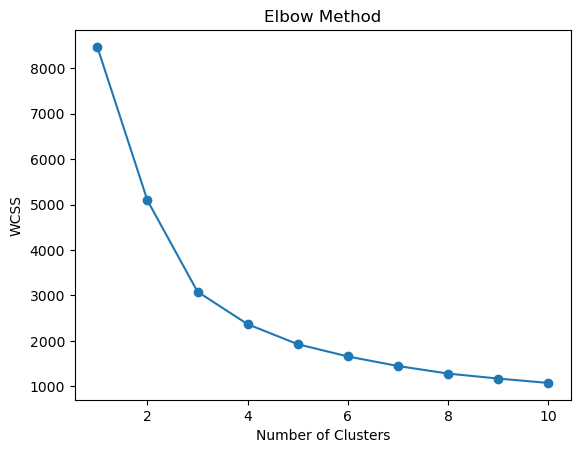

In [13]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [15]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

data['KMeans_Cluster'] = kmeans.fit_predict(X)

print(data.head())

C:\Users\m3112\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(


   QUANTITYORDERED  PRICEEACH    SALES  KMeans_Cluster
0               30      95.70  2871.00               0
1               34      81.35  2765.90               0
2               41      94.74  3884.34               2
3               45      83.26  3746.70               1
4               49     100.00  5205.27               2


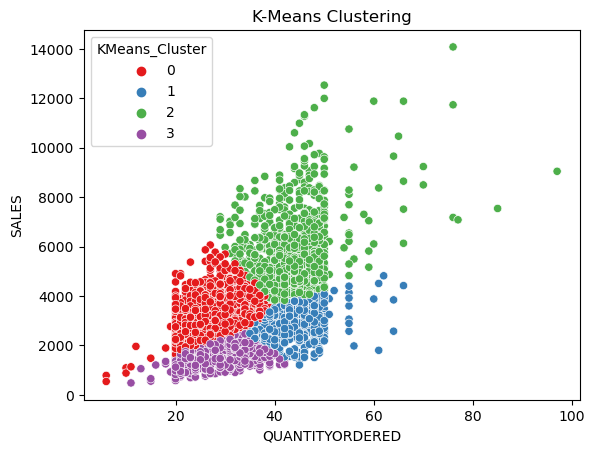

In [17]:
sns.scatterplot(
    x=data['QUANTITYORDERED'],
    y=data['SALES'],
    hue=data['KMeans_Cluster'],
    palette='Set1'
)

plt.title("K-Means Clustering")
plt.show()


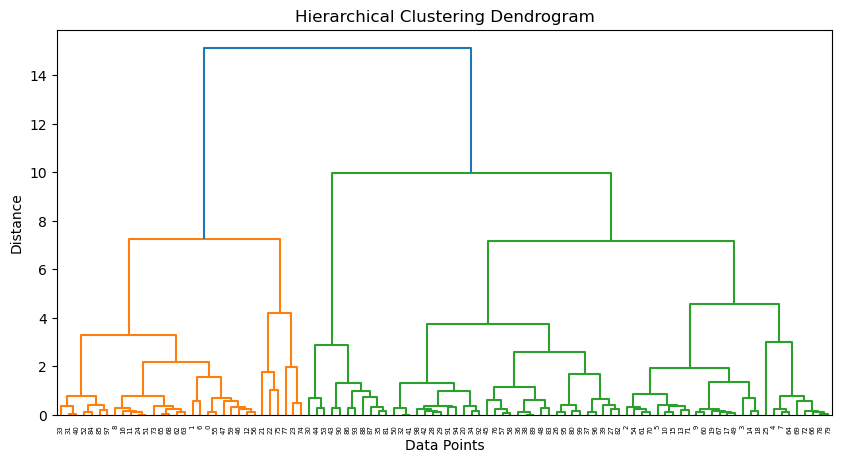

In [19]:
plt.figure(figsize=(10, 5))

Z = linkage(X[:100], method='ward')

dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

In [21]:
hc = AgglomerativeClustering(n_clusters=4, linkage='ward')

data['Hierarchical_Cluster'] = hc.fit_predict(X)

print(data.head())

   QUANTITYORDERED  PRICEEACH    SALES  KMeans_Cluster  Hierarchical_Cluster
0               30      95.70  2871.00               0                     0
1               34      81.35  2765.90               0                     0
2               41      94.74  3884.34               2                     1
3               45      83.26  3746.70               1                     3
4               49     100.00  5205.27               2                     1


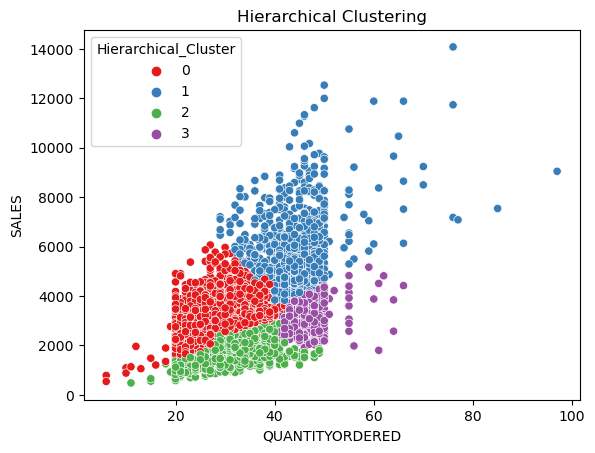

In [23]:
sns.scatterplot(
    x=data['QUANTITYORDERED'],
    y=data['SALES'],
    hue=data['Hierarchical_Cluster'],
    palette='Set1'
)

plt.title("Hierarchical Clustering")
plt.show()

In [25]:
print("K-Means Cluster Count:")
print(data['KMeans_Cluster'].value_counts())

print("\nHierarchical Cluster Count:")
print(data['Hierarchical_Cluster'].value_counts())

K-Means Cluster Count:
KMeans_Cluster
0    992
2    748
3    565
1    518
Name: count, dtype: int64

Hierarchical Cluster Count:
Hierarchical_Cluster
0    1124
1     685
2     675
3     339
Name: count, dtype: int64
